In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import LineString
from IPython.display import display, Markdown

In [2]:
# Load the data and print the first 5 rows
BIRDS_FILE = "../datasets/geospatial-learn-course-data/purple_martin.csv"

birds_df = pd.read_csv(BIRDS_FILE, parse_dates=['timestamp'])
n_unique = birds_df["tag-local-identifier"].nunique()

display(Markdown(f"There are _{n_unique}_ different birds in the dataset."))
birds_df.head()

There are _11_ different birds in the dataset.

,timestamp,location-long,location-lat,tag-local-identifier
0,2014-08-15 05:56:00,-88.146014,17.513049,30448
1,2014-09-01 05:59:00,-85.243501,13.095782,30448
2,2014-10-30 23:58:00,-62.906089,-7.852436,30448
3,2014-11-15 04:59:00,-61.776826,-11.723898,30448
4,2014-11-30 09:59:00,-61.241538,-11.612237,30448


In [3]:
# Create the GeoDataFrame
# Set the CRS to {'init': 'epsg:4326'}
birds = gpd.GeoDataFrame(birds_df, crs='epsg:4326',
                         geometry=gpd.points_from_xy(birds_df['location-long'], birds_df['location-lat']))

In [4]:
# Load a GeoDataFrame with country boundaries in North/South America, print the first 5 rows
WORLD_FILE = '../datasets/geospatial-learn-course-data/naturalearth_lowres/naturalearth_lowres.shp'
world = gpd.read_file(WORLD_FILE)
americas = world.loc[world['continent'].isin(['North America', 'South America'])]
americas.head()

,pop_est,continent,name,iso_a3,gdp_md_est,geometry
3,35623680,North America,Canada,CAN,1674000.0,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,326625791,North America,United States of America,USA,18560000.0,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."
9,44293293,South America,Argentina,ARG,879400.0,"MULTIPOLYGON (((-68.63401 -52.63637, -68.25 -5..."
10,17789267,South America,Chile,CHL,436100.0,"MULTIPOLYGON (((-68.63401 -52.63637, -68.63335..."
16,10646714,North America,Haiti,HTI,19340.0,"POLYGON ((-71.71236 19.71446, -71.62487 19.169..."


<Axes: >

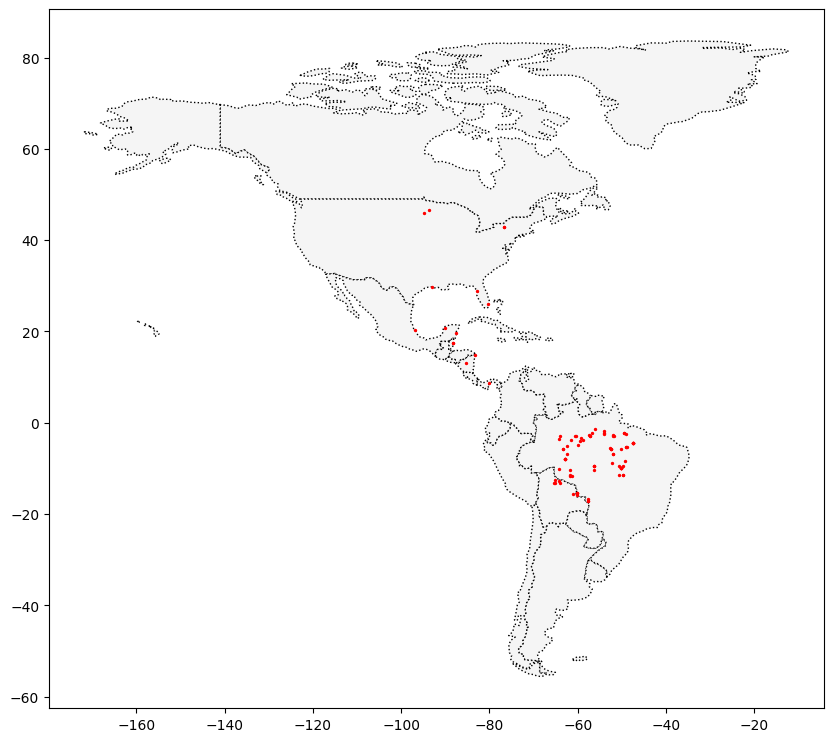

In [5]:
# create a single plot that shows both: 
# 1) the country boundaries in the americas GeoDataFrame, and 
# 2) all of the points in the birds_gdf GeoDataFrame.
ax = americas.plot(figsize=(10,10), color='whitesmoke', edgecolor='black', linestyle=':')
birds.plot(ax=ax, color='red', markersize=2)

In [6]:
CRS = 'epsg:4326'
# GeoDataFrame showing path for each bird
path_df = (birds
           .groupby("tag-local-identifier")['geometry']
           .apply(list)
           .apply(lambda x: LineString(x))
           .reset_index())
path_gdf = gpd.GeoDataFrame(path_df, crs=CRS, geometry=path_df.geometry)

# GeoDataFrame showing starting point for each bird
start_df = (birds
            .groupby("tag-local-identifier")['geometry']
            .apply(list).apply(lambda x: x[0])
            .reset_index())
start_gdf = gpd.GeoDataFrame(start_df, crs=CRS, geometry=start_df.geometry)

start_gdf.head()

,tag-local-identifier,geometry
0,30048,POINT (-90.12992 20.73242)
1,30054,POINT (-93.60861 46.50563)
2,30198,POINT (-80.31036 25.92545)
3,30263,POINT (-76.78146 42.99208)
4,30275,POINT (-76.78213 42.99207)


In [7]:
# create a GeoDataFrame `end_gdf` containing the final location of each bird.  
# - The format should be identical to that of `start_gdf`, with two columns 
#   ("tag-local-identifier" and "geometry"), where the "geometry" column contains Point objects.
# - Set the CRS of `end_gdf` to `{'init': 'epsg:4326'}`.
end_df = (birds
          .groupby("tag-local-identifier")['geometry']
          .apply(list).apply(lambda x: x[-1])
          .reset_index())
end_gdf = gpd.GeoDataFrame(end_df, crs=CRS, geometry=end_df.geometry)

end_gdf.head()

,tag-local-identifier,geometry
0,30048,POINT (-47.53632 -4.43758)
1,30054,POINT (-62.47914 -5.0384)
2,30198,POINT (-57.46417 -2.77617)
3,30263,POINT (-50.1923 -5.70504)
4,30275,POINT (-57.70404 -16.72336)


<Axes: >

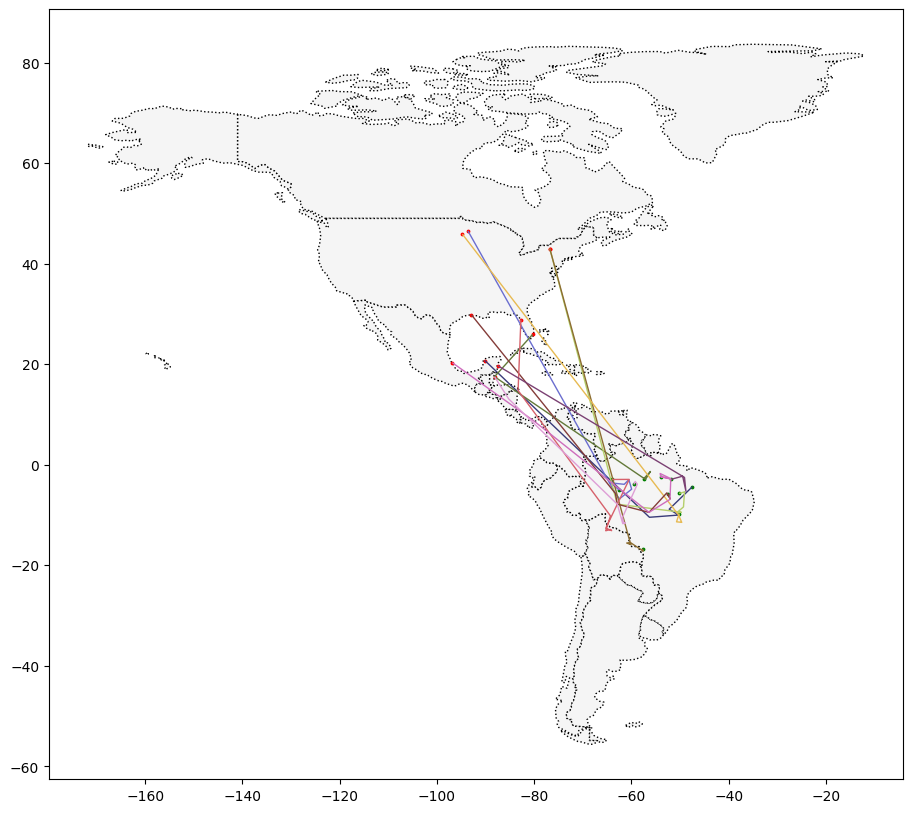

In [8]:
# Use the path_gdf, start_gdf, and end_gdf GeoDataFrames to visualize the paths of all birds on a single map.
ax = americas.plot(figsize=(12, 10), color='whitesmoke', edgecolor='black', linestyle=':')
start_gdf.plot(ax=ax, color='red', markersize=3)
end_gdf.plot(ax=ax, color='green', markersize=3)
path_gdf.plot(ax=ax,linestyle='-', linewidth=1, cmap='tab20b')

In [9]:
# Create a GeoDataFrame protected_areas containing the locations of all of the protected areas in South America.
PROTECTED_FILE = "../datasets/geospatial-learn-course-data/SAPA_Aug2019-shapefile/SAPA_Aug2019-shapefile-polygons.shp"

protected_areas = gpd.read_file(PROTECTED_FILE)
protected_areas.head()


,WDPAID,WDPA_PID,PA_DEF,NAME,ORIG_NAME,DESIG,DESIG_ENG,DESIG_TYPE,IUCN_CAT,INT_CRIT,...,GOV_TYPE,OWN_TYPE,MANG_AUTH,MANG_PLAN,VERIF,METADATAID,SUB_LOC,PARENT_ISO,ISO3,geometry
0,14067.0,14067,1,Het Spaans Lagoen,Het Spaans Lagoen,"Ramsar Site, Wetland of International Importance","Ramsar Site, Wetland of International Importance",International,Not Reported,Not Reported,...,Not Reported,Not Reported,Not Reported,Management plan is not implemented and not ava...,State Verified,1856,Not Reported,NLD,ABW,"POLYGON ((-69.97523 12.47379, -69.97523 12.473..."
1,14003.0,14003,1,Bubali Pond Bird Sanctuary,Bubali Pond Bird Sanctuary,Bird Sanctuary,Bird Sanctuary,National,Not Reported,Not Applicable,...,Not Reported,Not Reported,Not Reported,Not Reported,State Verified,1899,Not Reported,NLD,ABW,"POLYGON ((-70.04734 12.56329, -70.04615 12.563..."
2,555624439.0,555624439,1,Arikok National Park,Arikok National Park,National Park,National Park,National,Not Reported,Not Applicable,...,Non-profit organisations,Non-profit organisations,Fundacion Parke Nacional Arikok,Not Reported,State Verified,1899,Not Reported,NLD,ABW,"MULTIPOLYGON (((-69.96302 12.48384, -69.96295 ..."
3,303894.0,303894,1,Madidi,Madidi,Area Natural de Manejo Integrado,Natural Integrated Management Area,National,Not Reported,Not Applicable,...,Federal or national ministry or agency,Not Reported,Not Reported,Not Reported,State Verified,1860,BO-L,BOL,BOL,"POLYGON ((-68.5906 -14.43388, -68.59062 -14.43..."
4,303893.0,303893,1,Apolobamba,Apolobamba,Area Natural de Manejo Integado Nacional,National Natural Integrated Management Area,National,Not Reported,Not Applicable,...,Federal or national ministry or agency,Not Reported,Not Reported,Not Reported,State Verified,1860,BO-L,BOL,BOL,"POLYGON ((-69.20949 -14.73334, -69.2013 -14.73..."


<Axes: >

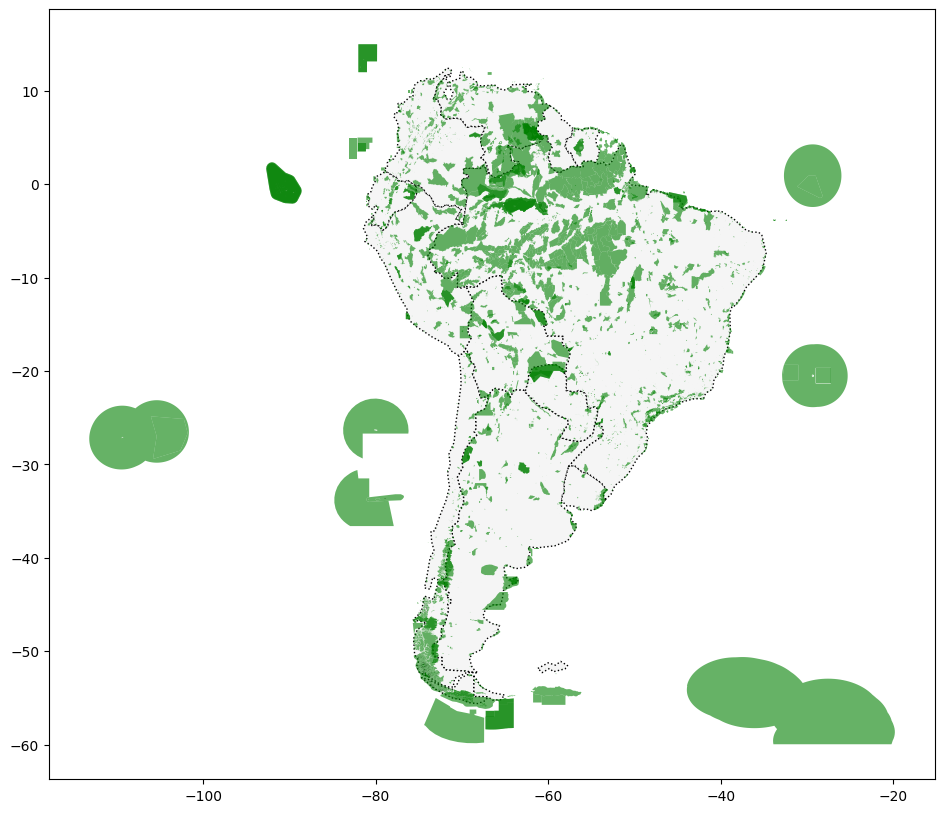

In [10]:
# Country boundaries in South America
south_america = americas.loc[americas['continent']=='South America']

# Plot protected areas in South America
ax = south_america.plot(figsize=(12,10), color='whitesmoke', edgecolor='black', linestyle=':')
protected_areas.plot(ax=ax, color='green', alpha=0.6)

In [11]:
# Calculate the total area of all protected lands in South America (not including marine area). To do this,
# use the "REP_AREA" and "REP_M_AREA" columns, which contain the total area and total marine area, respectively,
# in square kilometers.
P_Area = sum(protected_areas['REP_AREA']-protected_areas['REP_M_AREA'])
print(f"South America has {P_Area} square kilometers of protected areas.")

South America has 5396761.9116883585 square kilometers of protected areas.


In [12]:
south_america.head()

,pop_est,continent,name,iso_a3,gdp_md_est,geometry
9,44293293,South America,Argentina,ARG,879400.0,"MULTIPOLYGON (((-68.63401 -52.63637, -68.25 -5..."
10,17789267,South America,Chile,CHL,436100.0,"MULTIPOLYGON (((-68.63401 -52.63637, -68.63335..."
20,2931,South America,Falkland Is.,FLK,281.8,"POLYGON ((-61.2 -51.85, -60 -51.25, -59.15 -51..."
28,3360148,South America,Uruguay,URY,73250.0,"POLYGON ((-57.62513 -30.21629, -56.97603 -30.1..."
29,207353391,South America,Brazil,BRA,3081000.0,"POLYGON ((-53.37366 -33.76838, -53.65054 -33.2..."


In [13]:
# Calculate the total area of South America (in square kilometers)
totalArea = sum(south_america.geometry.to_crs(epsg=3035).area) / 1e6

In [14]:
# What percentage of South America is protected?
percentage_protected = P_Area/totalArea
print(f'Approximately {round(percentage_protected*100, 2)}% of South America is protected.')

Approximately 30.39% of South America is protected.


<Axes: >

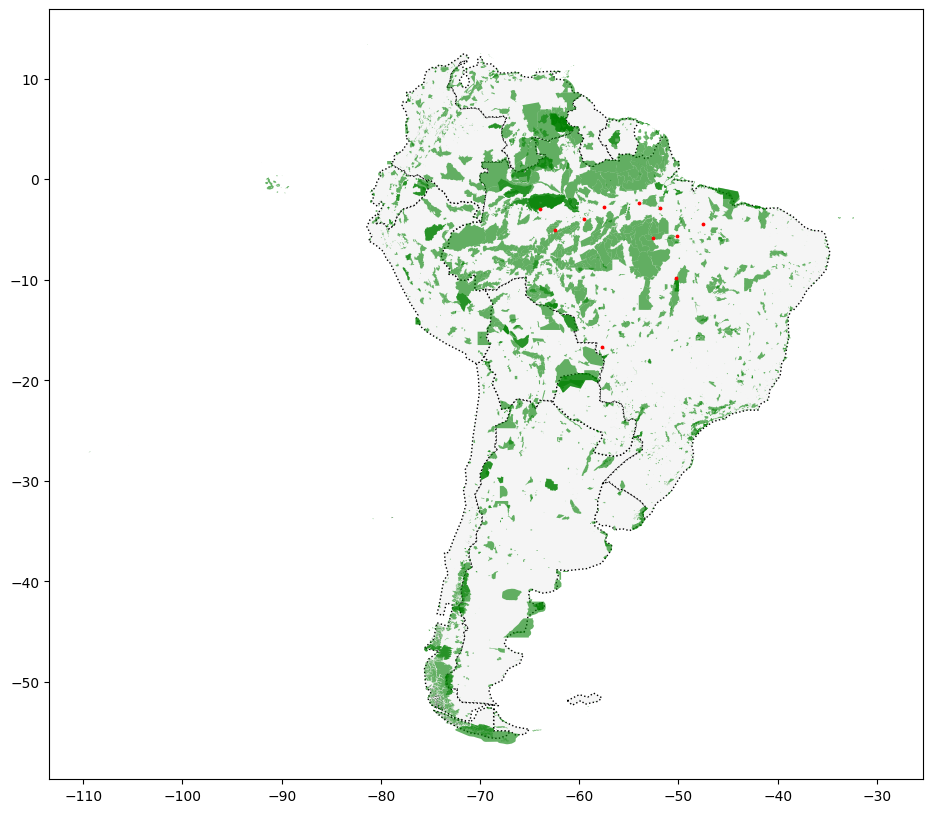

In [15]:
# Create a plot that shows for all birds, all of the locations where they were discovered in South America. 
# Also plot the locations of all protected areas in South America.
#
# To exclude protected areas that are purely marine areas (with no land component), you can use the 
# "MARINE" column (and plot only the rows in protected_areas[protected_areas['MARINE']!='2'], 
# instead of every row in the protected_areas GeoDataFrame).

land_protected_areas = protected_areas[protected_areas['MARINE']!='2']

ax = south_america.plot(figsize=(12, 10), color='whitesmoke', edgecolor='black', linestyle=':')
land_protected_areas.plot(ax=ax, color='green', alpha=0.6)
end_gdf.plot(ax=ax, color='red', markersize=3)